# Project 10 — Course Registration System

## Project Overview
The Course Registration System is a Python-based application developed using Object-Oriented Programming (OOP). It helps manage students, courses, and course registrations through a simple menu-driven interface.

## Features
- **Add Students:** Add new students with unique student IDs.
- **Add Courses:** Create courses with course IDs, names, and fees.
- **Register for Courses:** Enroll students in available courses.
- **Drop Courses:** Allow students to withdraw from registered courses.
- **Display Information:** View student details, available courses, and registration records.
- **Data Persistence:** Automatically save and load student, course, and registration data using JSON files.

## Technologies Used
- Python
- Object-Oriented Programming (Classes and Objects)
- Functions and Loops
- Dictionaries and Lists
- JSON for Data Storage

## Objective
The main objective of this project is to demonstrate the practical application of Python OOP concepts while developing a simple system for managing course registrations and maintaining data between sessions.



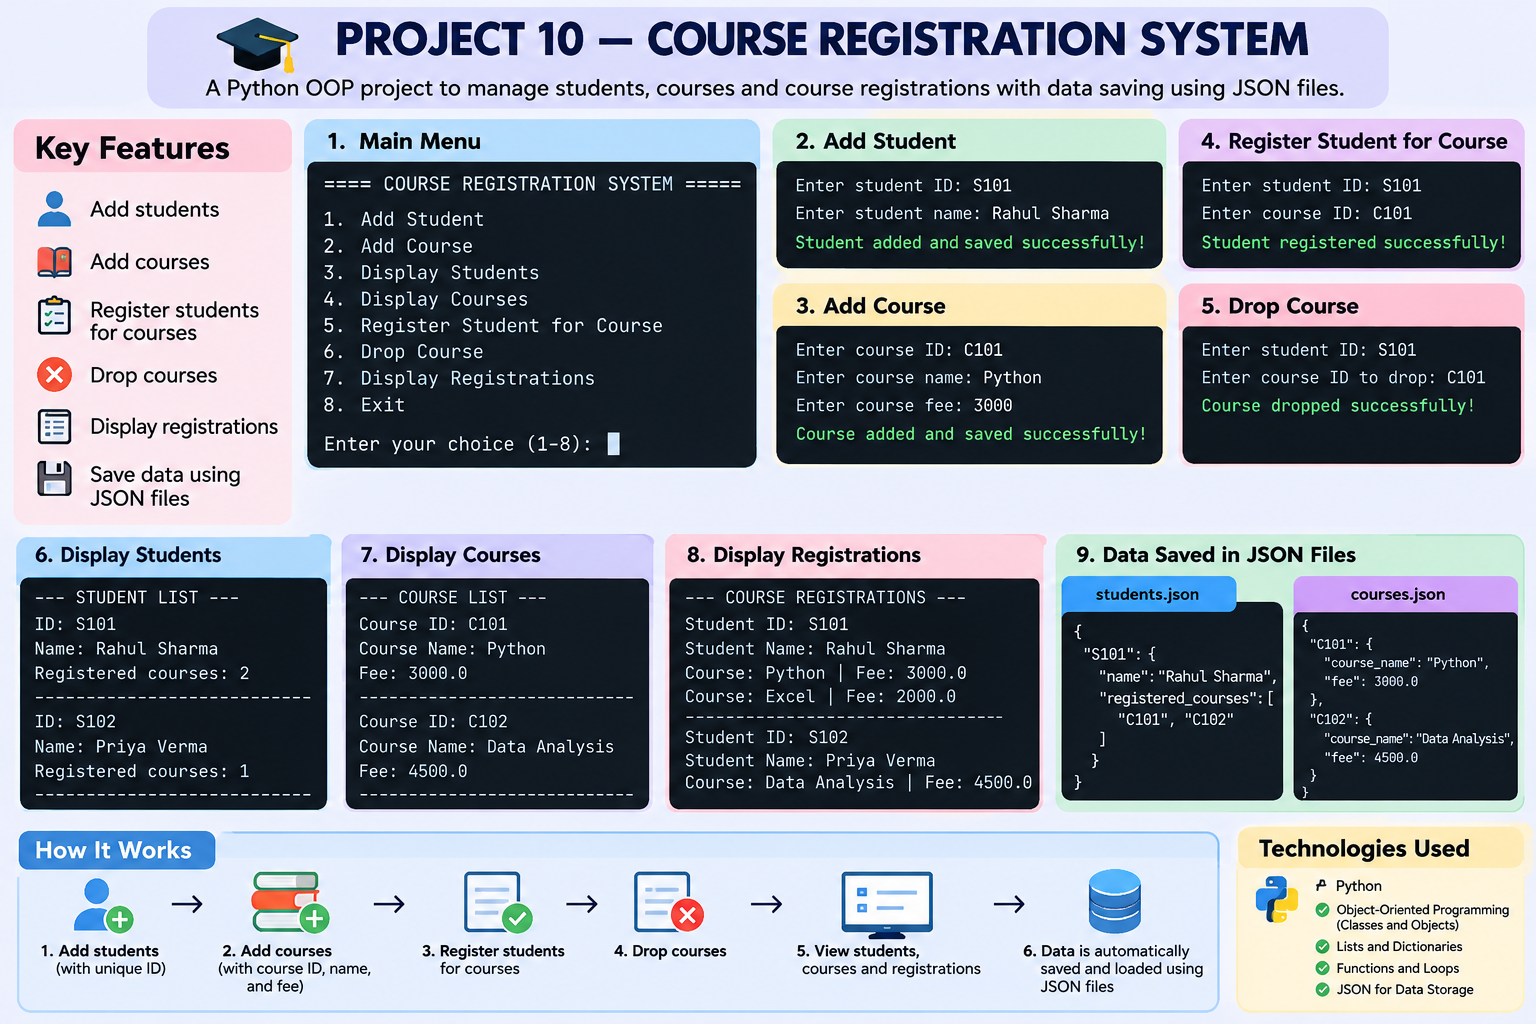

In [ ]:
import json
import os


# =========================================================
# CLASS 1: STUDENT
# =========================================================

class Student:
    def __init__(self, student_id, name):
        self.student_id = student_id
        self.name = name
        self.registered_courses = []


# =========================================================
# CLASS 2: COURSE
# =========================================================

class Course:
    def __init__(self, course_id, course_name, fee):
        self.course_id = course_id
        self.course_name = course_name
        self.fee = fee


# =========================================================
# CLASS 3: REGISTRATION SYSTEM
# =========================================================

class RegistrationSystem:

    def __init__(self):
        self.students = {}
        self.courses = {}

        self.students_file = "students.json"
        self.courses_file = "courses.json"

        self.load_data()


    # -----------------------------------------------------
    # SAVE STUDENT DATA
    # -----------------------------------------------------

    def save_students(self):

        data = {}

        for student_id, student in self.students.items():

            data[student_id] = {
                "name": student.name,
                "registered_courses": student.registered_courses
            }

        with open(self.students_file, "w") as file:
            json.dump(data, file, indent=4)


    # -----------------------------------------------------
    # SAVE COURSE DATA
    # -----------------------------------------------------

    def save_courses(self):

        data = {}

        for course_id, course in self.courses.items():

            data[course_id] = {
                "course_name": course.course_name,
                "fee": course.fee
            }

        with open(self.courses_file, "w") as file:
            json.dump(data, file, indent=4)


    # -----------------------------------------------------
    # LOAD SAVED DATA
    # -----------------------------------------------------

    def load_data(self):

        # Load students
        if os.path.exists(self.students_file):

            try:
                with open(self.students_file, "r") as file:
                    data = json.load(file)

                # Only load if JSON contains a dictionary
                if isinstance(data, dict):

                    for student_id, details in data.items():

                        student = Student(
                            student_id,
                            details["name"]
                        )

                        student.registered_courses = details.get(
                            "registered_courses", []
                        )

                        self.students[student_id] = student

            except (json.JSONDecodeError, KeyError, TypeError):
                print("Student file could not be loaded. Starting with empty student data.")


        # Load courses
        if os.path.exists(self.courses_file):

            try:
                with open(self.courses_file, "r") as file:
                    data = json.load(file)

                # Only load if JSON contains a dictionary
                if isinstance(data, dict):

                    for course_id, details in data.items():

                        course = Course(
                            course_id,
                            details["course_name"],
                            details["fee"]
                        )

                        self.courses[course_id] = course

            except (json.JSONDecodeError, KeyError, TypeError):
                print("Course file could not be loaded. Starting with empty course data.")


    # -----------------------------------------------------
    # ADD STUDENT
    # -----------------------------------------------------

    def add_student(self):

        student_id = input("Enter student ID: ").strip()

        if student_id == "":
            print("Student ID cannot be empty.")
            return

        if student_id in self.students:
            print("Student ID already exists.")
            return

        name = input("Enter student name: ").strip()

        if name == "":
            print("Student name cannot be empty.")
            return

        student = Student(student_id, name)

        self.students[student_id] = student

        self.save_students()

        print("Student added and saved successfully!")


    # -----------------------------------------------------
    # ADD COURSE
    # -----------------------------------------------------

    def add_course(self):

        course_id = input("Enter course ID: ").strip()

        if course_id == "":
            print("Course ID cannot be empty.")
            return

        if course_id in self.courses:
            print("Course ID already exists.")
            return

        course_name = input("Enter course name: ").strip()

        if course_name == "":
            print("Course name cannot be empty.")
            return

        try:
            fee = float(input("Enter course fee: "))

            if fee < 0:
                print("Course fee cannot be negative.")
                return

        except ValueError:
            print("Please enter a valid number for course fee.")
            return

        course = Course(
            course_id,
            course_name,
            fee
        )

        self.courses[course_id] = course

        self.save_courses()

        print("Course added and saved successfully!")


    # -----------------------------------------------------
    # DISPLAY STUDENTS
    # -----------------------------------------------------

    def display_students(self):

        if not self.students:
            print("No students available.")
            return

        print("\n===== STUDENT LIST =====")

        for student in self.students.values():

            print("Student ID:", student.student_id)
            print("Student Name:", student.name)
            print(
                "Number of Registered Courses:",
                len(student.registered_courses)
            )

            print("-" * 35)


    # -----------------------------------------------------
    # DISPLAY COURSES
    # -----------------------------------------------------

    def display_courses(self):

        if not self.courses:
            print("No courses available.")
            return

        print("\n===== COURSE LIST =====")

        for course in self.courses.values():

            print("Course ID:", course.course_id)
            print("Course Name:", course.course_name)
            print("Course Fee:", course.fee)

            print("-" * 35)


    # -----------------------------------------------------
    # REGISTER STUDENT FOR COURSE
    # -----------------------------------------------------

    def register_student(self):

        student_id = input("Enter student ID: ").strip()

        if student_id not in self.students:
            print("Student not found.")
            return

        course_id = input("Enter course ID: ").strip()

        if course_id not in self.courses:
            print("Course not found.")
            return

        student = self.students[student_id]

        if course_id in student.registered_courses:
            print("Student is already registered for this course.")
            return

        student.registered_courses.append(course_id)

        self.save_students()

        print("Student registered successfully!")


    # -----------------------------------------------------
    # DROP COURSE
    # -----------------------------------------------------

    def drop_course(self):

        student_id = input("Enter student ID: ").strip()

        if student_id not in self.students:
            print("Student not found.")
            return

        course_id = input("Enter course ID to drop: ").strip()

        student = self.students[student_id]

        if course_id not in student.registered_courses:
            print("Student is not registered for this course.")
            return

        student.registered_courses.remove(course_id)

        self.save_students()

        print("Course dropped successfully!")


    # -----------------------------------------------------
    # DISPLAY REGISTRATIONS
    # -----------------------------------------------------

    def display_registrations(self):

        if not self.students:
            print("No students available.")
            return

        print("\n===== COURSE REGISTRATIONS =====")

        registration_found = False

        for student in self.students.values():

            if student.registered_courses:

                registration_found = True

                print("\nStudent ID:", student.student_id)
                print("Student Name:", student.name)

                for course_id in student.registered_courses:

                    if course_id in self.courses:

                        course = self.courses[course_id]

                        print(
                            "Course:",
                            course.course_name,
                            "| Fee:",
                            course.fee
                        )

                print("-" * 35)

        if not registration_found:
            print("No course registrations available.")


# =========================================================
# CREATE OBJECT
# =========================================================

system = RegistrationSystem()


# =========================================================
# MAIN MENU
# =========================================================

while True:

    print("\n====================================")
    print("     COURSE REGISTRATION SYSTEM")
    print("====================================")

    print("1. Add Student")
    print("2. Add Course")
    print("3. Display Students")
    print("4. Display Courses")
    print("5. Register Student for Course")
    print("6. Drop Course")
    print("7. Display Registrations")
    print("8. Exit")

    choice = input("\nEnter your choice (1-8): ").strip()


    if choice == "1":

        system.add_student()


    elif choice == "2":

        system.add_course()


    elif choice == "3":

        system.display_students()


    elif choice == "4":

        system.display_courses()


    elif choice == "5":

        system.register_student()


    elif choice == "6":

        system.drop_course()


    elif choice == "7":

        system.display_registrations()


    elif choice == "8":

        system.save_students()
        system.save_courses()

        print("\nData saved successfully!")
        print("Thank you for using the Course Registration System.")

        break


    else:

        print("Invalid choice. Please enter a number from 1 to 8.")


     COURSE REGISTRATION SYSTEM
1. Add Student
2. Add Course
3. Display Students
4. Display Courses
5. Register Student for Course
6. Drop Course
7. Display Registrations
8. Exit



Enter your choice (1-8):  1
Enter student ID:  1001
Enter student name:  Shriya Verma


Student added and saved successfully!

     COURSE REGISTRATION SYSTEM
1. Add Student
2. Add Course
3. Display Students
4. Display Courses
5. Register Student for Course
6. Drop Course
7. Display Registrations
8. Exit



Enter your choice (1-8):  2
Enter course ID:  Data Analytics with Gen AI
Enter course name:  Data Analytics
Enter course fee:  50000


Course added and saved successfully!

     COURSE REGISTRATION SYSTEM
1. Add Student
2. Add Course
3. Display Students
4. Display Courses
5. Register Student for Course
6. Drop Course
7. Display Registrations
8. Exit



Enter your choice (1-8):  3


... (3 outputs left out)


Enter your choice (1-8):  5
Enter student ID:  1002


Student not found.

     COURSE REGISTRATION SYSTEM
1. Add Student
2. Add Course
3. Display Students
4. Display Courses
5. Register Student for Course
6. Drop Course
7. Display Registrations
8. Exit



Enter your choice (1-8):  6
Enter student ID:  1001
Enter course ID to drop:  1001


Student is not registered for this course.

     COURSE REGISTRATION SYSTEM
1. Add Student
2. Add Course
3. Display Students
4. Display Courses
5. Register Student for Course
6. Drop Course
7. Display Registrations
8. Exit
